A static magnetic field $B$ along the quantisation axis shifts each sublevel by

$$
E_{F,m_F} = g_F \, m_F \, \mu_B B ,
$$

which is diagonal in the bare Hamiltonian, so it is just an extra term added to the level energies. It splits the lines of $\sigma^+$ and $\sigma^-$ light by different amounts, the basis of magnetometry and magneto-optical rotation.

::: {.callout-note}
## Sign convention
The sign is that of Steck's alkali data: the shift is $+g_F m_F \mu_B B$, so the Rb87 $5S_{1/2}$ $F=2$ level has $g_F=+1/2$ and its $m_F=+2$ sublevel moves *up* in energy for $B>0$. Some references (e.g. Budker et al.) define the magnetic moment with the opposite sign and tabulate $g_F$ with the opposite sign, so check the convention when importing values.
:::

**Units.** The code is in natural units, so `magnitude` with `"units": "natural"` (the default) is $\mu_B B/h$ in the same frequency unit as `energies`, and the shift is $g_F m_F B$ in that unit. If your energies are in MHz (time in microseconds), use `"units": "gauss"` and clerq converts with $\mu_B/h = 1.3996$ MHz/G. The helper `hyperfine.gauss_to_natural` does the same conversion.

Only a scalar field along the quantisation axis is supported: no transverse fields, no other quantisation axis, and no Breit-Rabi nonlinearity (so keep $g_F m_F \mu_B B$ small compared with the hyperfine splittings).

## A two-level example

Levels are given a `g_F` and an `m_F` in the `b_field` block of the system. We use a ground level with $g_F m_F = -1/2$ and an excited level with $g_F m_F = 3/2$, so the line is shifted by $(3/2 - (-1/2))B = 2B$.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

from clerq import PropagationSolver, spectral


def problem(B):
    return {
        "system": {
            "num_states": 2,
            "decays": [{"channels": [[0, 1]], "rate": 1.0}],
            "fields": [
                {
                    "coupled_levels": [[0, 1]],
                    "rabi_freq": 1.0e-3,
                    "rabi_freq_t_func": "gaussian",
                    "rabi_freq_t_args": {"ampl": 1.0, "centre": 0.0, "fwhm": 0.05},
                }
            ],
            "b_field": {
                "magnitude": B,
                "units": "natural",
                "g_F": [-0.5, 1.5],
                "m_F": [1.0, 1.0],
            },
        },
        "t_min": -2.0,
        "t_max": 30.0,
        "t_steps": 3200,
        "z_min": -0.2,
        "z_max": 1.2,
        "z_steps": 20,
        "interaction_strengths": [0.5],
    }


def absorption_spectrum(p):
    solver = PropagationSolver.from_json_str(json.dumps(p))
    solver.solve(progress=False)
    return spectral.freq_list(solver), spectral.absorption(solver, 0, -1)

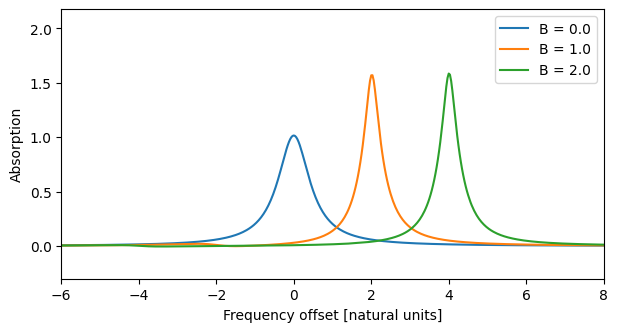

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for B in (0.0, 1.0, 2.0):
    freqs, absorb = absorption_spectrum(problem(B))
    ax.plot(freqs, absorb, label=f"B = {B}")
ax.set_xlim(-6, 8)
ax.set_ylim(-0.3, None)
ax.set_xlabel("Frequency offset [natural units]")
ax.set_ylabel("Absorption")
ax.legend();

The line moves by $2B$, as expected. Setting `magnitude` to 0 (or leaving out `b_field`) reproduces the field-free result exactly.

## Hyperfine levels

For alkali atoms `g_F` follows from the Landé formulae. Give each `LevelF` the orbital angular momentum `L` (or the fine-structure factor `g_J`) and the nuclear factor `g_I` in units of $\mu_B$ (Steck: $-0.0009951$ for Rb87), and `Atom1e.get_zeeman_levels()` returns the `g_F` and `m_F` lists for every sublevel, ready for `b_field`. A level can also be given its `g_F` directly.

Here is Rb87 $5S_{1/2}\,F=1 \to 5P_{1/2}\,F'=1$ with $\sigma^+$ and $\sigma^-$ probes. The ground level has $g_F=-1/2$ and the excited level $g_F=-1/6$, and the three ground sublevels are equally populated.

In [3]:
from clerq import hyperfine

g_I = -0.0009951
atom = hyperfine.Atom1e(element="Rb", isotope="87")
atom.add_F_level(hyperfine.LevelF(I=1.5, J=0.5, F=1, L=0, g_I=g_I))  # 5S1/2 F=1
atom.add_F_level(hyperfine.LevelF(I=1.5, J=0.5, F=1, L=1, g_I=g_I))  # 5P1/2 F'=1

print("g_F:", [round(f.g_F, 4) for f in atom.F_levels])
atom.get_zeeman_levels()

g_F: [-0.5018, -0.1677]


{'g_F': [-0.50182370109,
  -0.50182370109,
  -0.50182370109,
  -0.16771726630333333,
  -0.16771726630333333,
  -0.16771726630333333],
 'm_F': [-1.0, 0.0, 1.0, -1.0, 0.0, 1.0]}

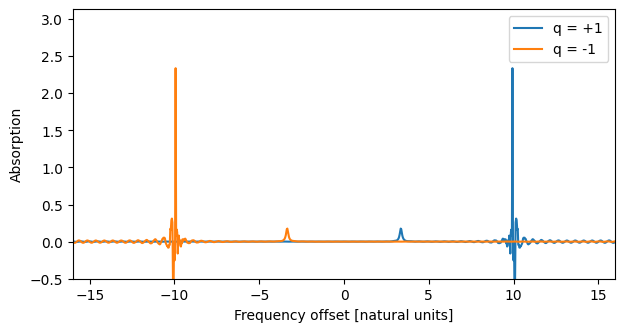

In [4]:
def hyperfine_problem(q, B):
    p = problem(B)
    coupled = atom.get_coupled_levels([0], [1])
    p["system"].update(
        {
            "num_states": 6,
            "decays": [
                {
                    "channels": coupled,
                    "rate": 1.0,
                    "factors": atom.get_decay_factors([0], [1]).tolist(),
                }
            ],
            "initial_state": [1 / 3] * 3 + [0.0] * 3,
            "b_field": {"magnitude": B, **atom.get_zeeman_levels()},
        }
    )
    p["system"]["fields"][0].update(
        {
            "coupled_levels": coupled,
            "factors": atom.get_clebsch_hf_factors([0], [1], q=q).tolist(),
        }
    )
    return p


fig, ax = plt.subplots(figsize=(7, 3.5))
for q in (1, -1):
    freqs, absorb = absorption_spectrum(hyperfine_problem(q, B=20.0))
    ax.plot(freqs, absorb, label=f"q = {q:+d}")
ax.set_xlim(-16, 16)
ax.set_ylim(-0.5, None)
ax.set_xlabel("Frequency offset [natural units]")
ax.set_ylabel("Absorption")
ax.legend();

Each polarisation has two lines, one for each allowed pair of sublevels, at $(g_{F'} m_{F'} - g_F m_F)B$. They sit at mirror-image positions for the two polarisations, which is what makes the medium circularly birefringent. (In clerq's convention $q=+1$ couples $m_F \to m_F - 1$.)

## Differentiating with respect to B

With `to_autodiff()` (see [autodiff recipes](autodiff-recipes.ipynb)), the field is a differentiable parameter named `b_field`, in natural units: the bare Hamiltonian is $H_0 = H_\mathrm{base} + 2\pi B Z$ with $Z=\mathrm{diag}(g_F m_F)$. The shift is read from the system, so `solve()` and the autodiff version agree at any $B$.

In [5]:
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

p = problem(0.7)
p["t_min"], p["t_max"], p["t_steps"], p["z_steps"] = -1.0, 4.0, 60, 4
p["system"]["fields"][0]["rabi_freq_t_args"]["fwhm"] = 0.4
p["system"]["fields"][0]["rabi_freq"] = 0.5
p["interaction_strengths"] = [2.0]
solver = PropagationSolver.from_json_str(json.dumps(p))
ad = solver.to_autodiff()


def transmitted_energy(omega):
    return jnp.sum(jnp.abs(omega[0, -1]) ** 2)


value, grads = ad.value_and_grad(transmitted_energy, {"b_field": 0.7})
value, grads["b_field"]

(Array(1.0354147, dtype=float64),
 Array(0.37402203, dtype=float64, weak_type=True))